# Task 3 (Part 1): Python Data Visualization
**ApexPlanet Software Pvt. Ltd. | Data Analytics Internship**
**Dataset:** IBM Telco Customer Churn (cleaned in Task 1)

This notebook creates **18 visualizations**: 7 with Matplotlib, 5 with Seaborn and 6 interactive Plotly charts (saved as HTML for sharing), plus one combined interactive dashboard page.
The Power BI / Tableau dashboard is Part 2 (see `POWERBI_GUIDE.md`).

**Run the cells from top to bottom.** The first code cell installs any missing library automatically (needs internet the first time).

> Telco has no dates and no geography, so "time" charts use **tenure month** (months since the customer joined).

## Step 0: Install missing libraries (automatic)
This cell checks each library and installs it into the **same Python the notebook is using** if it is missing.

In [1]:
import sys, subprocess, importlib

def ensure(import_name, pip_name=None):
    try:
        importlib.import_module(import_name)
        print(f"OK        {import_name}")
    except ImportError:
        print(f"Installing {pip_name or import_name} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", pip_name or import_name])
        print(f"Installed  {pip_name or import_name}")

for imp, pip in [("pandas", None), ("numpy", None), ("matplotlib", None), ("seaborn", None), ("plotly", None), ("nbformat", None)]:
    ensure(imp, pip)
print("\nAll libraries ready. If something was just installed and the next cell fails, click Restart and run again.")

OK        pandas
OK        numpy
OK        matplotlib
OK        seaborn
OK        plotly
Installing nbformat ...
Installed  nbformat

All libraries ready. If something was just installed and the next cell fails, click Restart and run again.


## Setup

In [2]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (8, 5)
print("Libraries ready")

Libraries ready


In [3]:
MANUAL_PATH = ""     # example: r"C:\Users\YourName\Documents\apexplanet-data-analytics\data\processed\telco_churn_cleaned.csv"

if MANUAL_PATH:
    CSV_PATH = Path(MANUAL_PATH)
else:
    found = []
    for root in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]:
        found = list(root.rglob("telco_churn_cleaned.csv"))
        if found:
            break
    if not found:
        raise FileNotFoundError("telco_churn_cleaned.csv not found. Put it in data/processed/ or set MANUAL_PATH above.")
    CSV_PATH = found[0]

PROJECT_ROOT = CSV_PATH.parents[2] if CSV_PATH.parent.name == "processed" else CSV_PATH.parent
PNG_DIR  = PROJECT_ROOT / "reports" / "figures_task3"
HTML_DIR = PROJECT_ROOT / "dashboards" / "html"
PNG_DIR.mkdir(parents=True, exist_ok=True)
HTML_DIR.mkdir(parents=True, exist_ok=True)
print("CSV        :", CSV_PATH)
print("PNG folder :", PNG_DIR)
print("HTML folder:", HTML_DIR)

CSV        : c:\Users\Gaurav Pandey\OneDrive\Desktop\apexplanet\data\processed\telco_churn_cleaned.csv
PNG folder : c:\Users\Gaurav Pandey\OneDrive\Desktop\apexplanet\reports\figures_task3
HTML folder: c:\Users\Gaurav Pandey\OneDrive\Desktop\apexplanet\dashboards\html


In [4]:
df = pd.read_csv(CSV_PATH)
df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                            labels=["0-12", "13-24", "25-48", "49-72"])
print(df.shape)

def save_png(name):
    plt.tight_layout()
    plt.savefig(PNG_DIR / f"{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

def save_html(fig, name):
    fig.write_html(HTML_DIR / f"{name}.html", include_plotlyjs="cdn")
    print(f"Saved: {HTML_DIR / (name + '.html')}")
    try:
        fig.show()
    except Exception as e:
        print(f"(Inline preview skipped: {type(e).__name__}. The chart is saved - open the .html file in your browser.)")

# Reusable summary tables
by_tenure = (df[df["tenure"] >= 1].groupby("tenure")
             .agg(customers=("customer_id", "count"),
                  churn_rate=("churn_flag", lambda s: s.mean() * 100),
                  avg_bill=("monthly_charges", "mean"))
             .reset_index())
df.head()

(7043, 23)


,customer_id,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,...,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn,churn_flag,tenure_group
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0,0-12
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,Mailed check,56.95,1889.50,No,0,25-48
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,0-12
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0,25-48
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,0-12


# A. Matplotlib (7 charts)

### 1. Line plot: churn rate over tenure (trend over time)

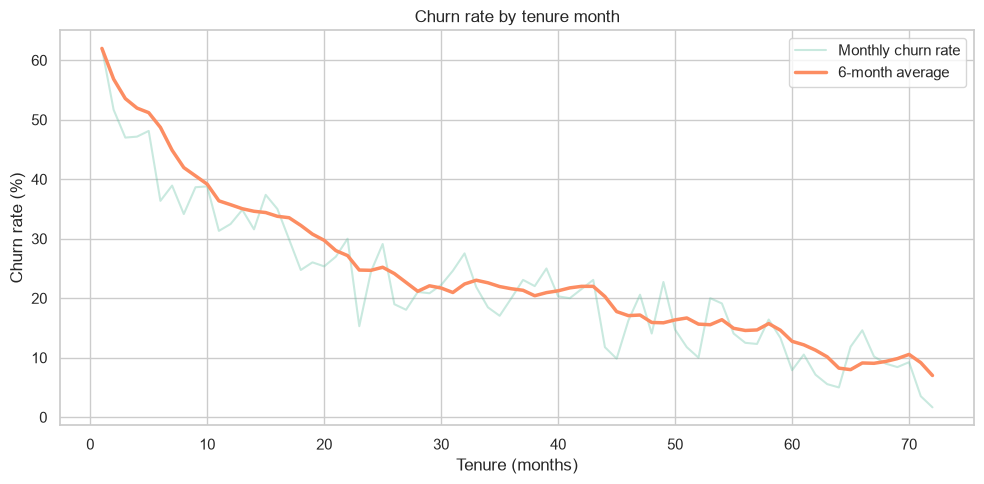

In [5]:
plt.figure(figsize=(10, 5))
plt.plot(by_tenure["tenure"], by_tenure["churn_rate"], alpha=0.35, label="Monthly churn rate")
plt.plot(by_tenure["tenure"], by_tenure["churn_rate"].rolling(6, min_periods=1).mean(), linewidth=2.5, label="6-month average")
plt.title("Churn rate by tenure month")
plt.xlabel("Tenure (months)"); plt.ylabel("Churn rate (%)"); plt.legend()
save_png("01_line_churn_by_tenure")

### 2. Line plot: average monthly bill by tenure

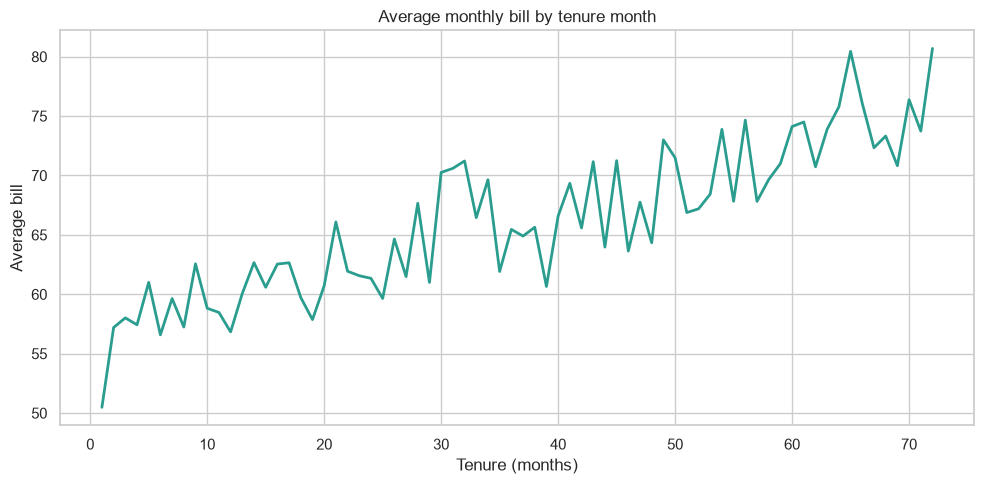

In [6]:
plt.figure(figsize=(10, 5))
plt.plot(by_tenure["tenure"], by_tenure["avg_bill"], color="#2a9d8f", linewidth=2)
plt.title("Average monthly bill by tenure month")
plt.xlabel("Tenure (months)"); plt.ylabel("Average bill")
save_png("02_line_avg_bill_by_tenure")

### 3. Bar chart: customers by contract (comparison)

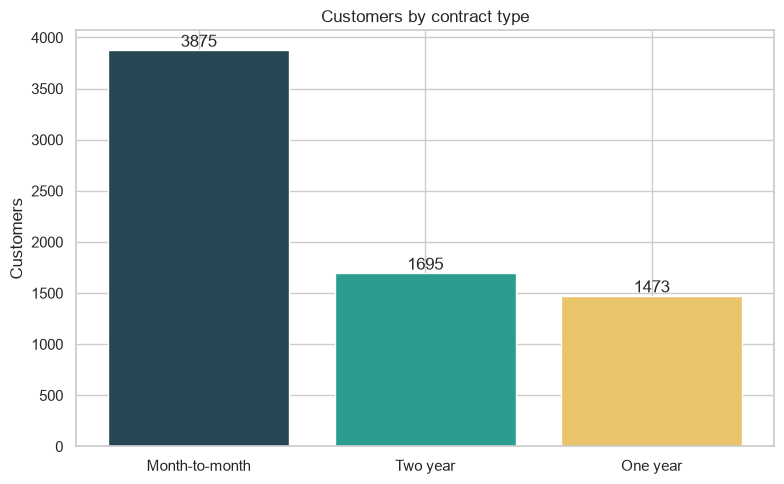

In [7]:
counts = df["contract"].value_counts()
plt.figure(figsize=(8, 5))
bars = plt.bar(counts.index, counts.values, color=["#264653", "#2a9d8f", "#e9c46a"])
plt.bar_label(bars, fmt="%d")
plt.title("Customers by contract type"); plt.ylabel("Customers")
save_png("03_bar_customers_by_contract")

### 4. Bar chart: churn rate by internet service

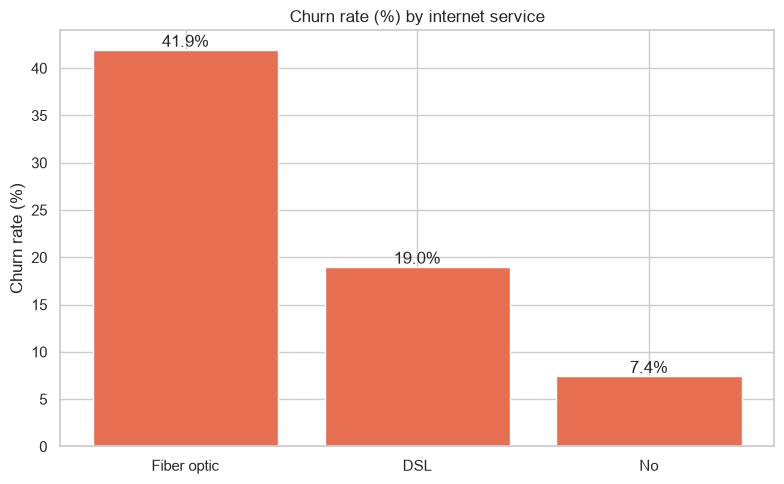

In [8]:
rate = df.groupby("internet_service")["churn_flag"].mean().mul(100).sort_values(ascending=False)
plt.figure(figsize=(8, 5))
bars = plt.bar(rate.index, rate.values, color="#e76f51")
plt.bar_label(bars, fmt="%.1f%%")
plt.title("Churn rate (%) by internet service"); plt.ylabel("Churn rate (%)")
save_png("04_bar_churn_by_internet")

### 5. Histogram: distribution of monthly charges

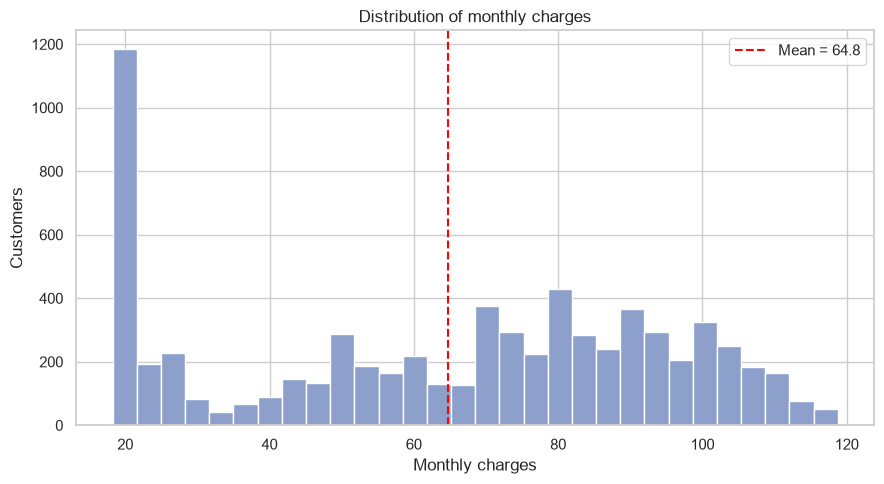

In [9]:
plt.figure(figsize=(9, 5))
plt.hist(df["monthly_charges"], bins=30, color="#8da0cb", edgecolor="white")
plt.axvline(df["monthly_charges"].mean(), color="red", linestyle="--", label=f"Mean = {df['monthly_charges'].mean():.1f}")
plt.title("Distribution of monthly charges"); plt.xlabel("Monthly charges"); plt.ylabel("Customers"); plt.legend()
save_png("05_hist_monthly_charges")

### 6. Scatter plot: tenure vs monthly charges (correlation)

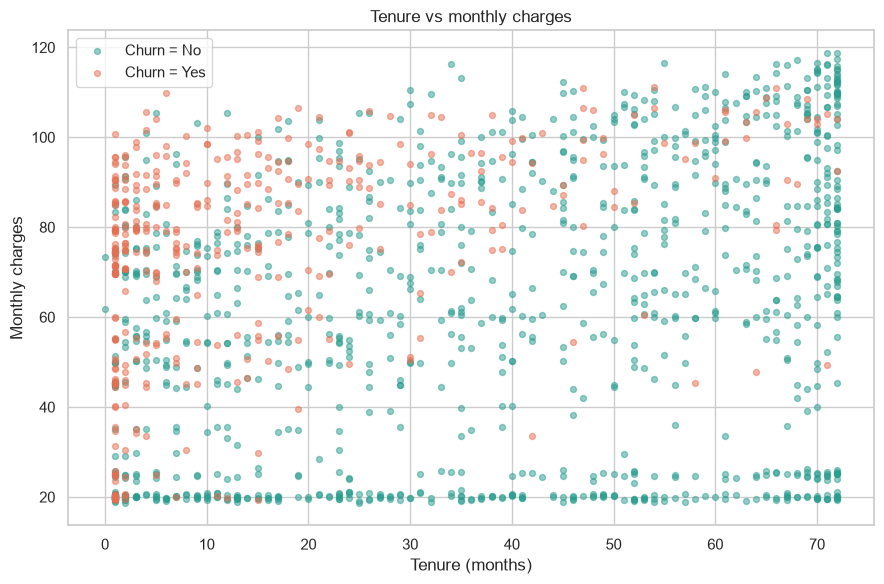

In [10]:
sample = df.sample(min(1500, len(df)), random_state=42)
plt.figure(figsize=(9, 6))
for label, color in [("No", "#2a9d8f"), ("Yes", "#e76f51")]:
    part = sample[sample["churn"] == label]
    plt.scatter(part["tenure"], part["monthly_charges"], alpha=0.5, s=18, c=color, label=f"Churn = {label}")
plt.title("Tenure vs monthly charges"); plt.xlabel("Tenure (months)"); plt.ylabel("Monthly charges"); plt.legend()
save_png("06_scatter_tenure_vs_charges")

### 7. Subplots: four charts together

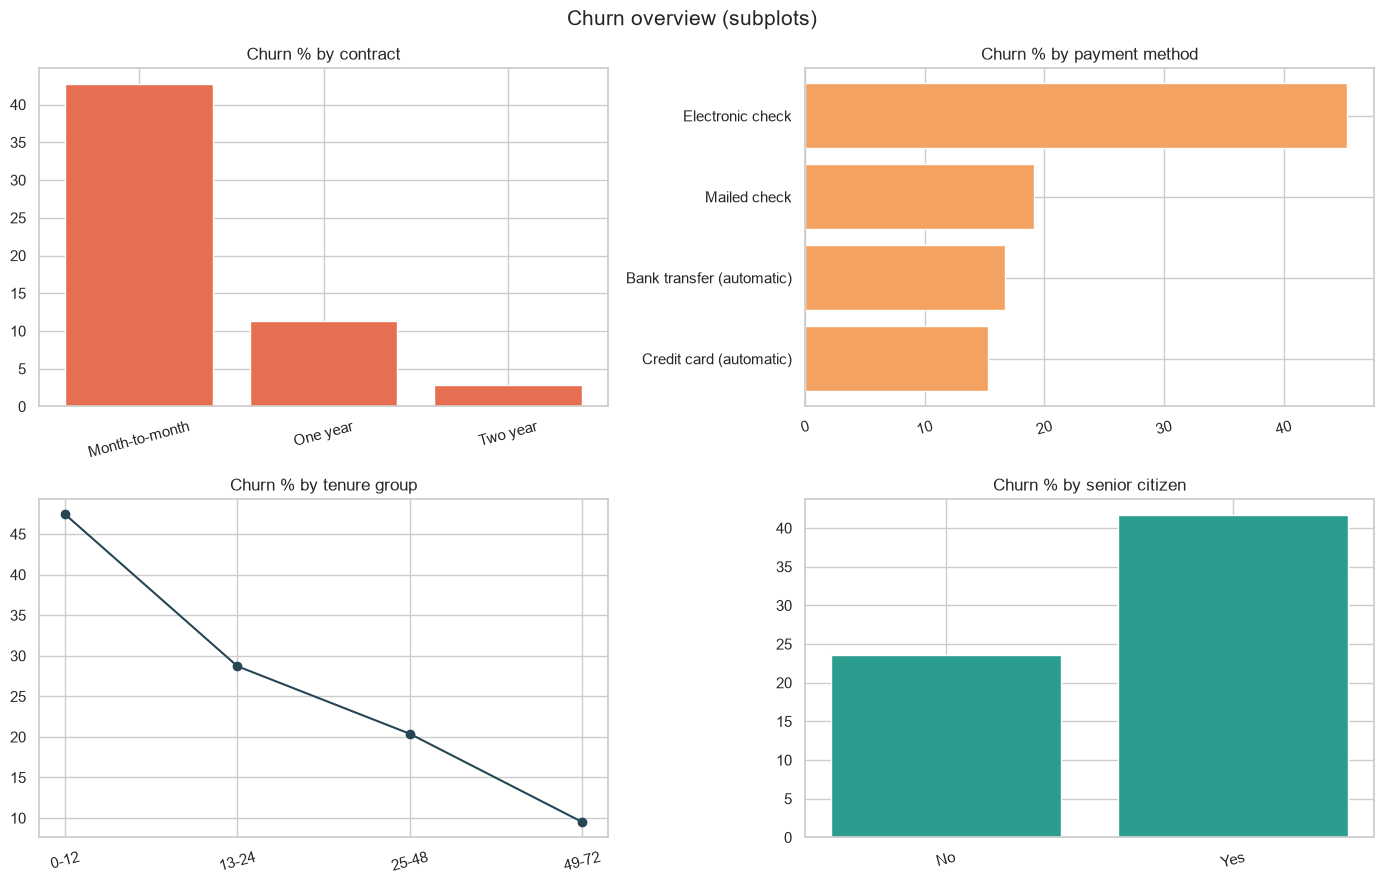

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

c = df.groupby("contract")["churn_flag"].mean().mul(100).sort_values(ascending=False)
axes[0, 0].bar(c.index, c.values, color="#e76f51"); axes[0, 0].set_title("Churn % by contract")

p = df.groupby("payment_method")["churn_flag"].mean().mul(100).sort_values()
axes[0, 1].barh(p.index, p.values, color="#f4a261"); axes[0, 1].set_title("Churn % by payment method")

t = df.groupby("tenure_group")["churn_flag"].mean().mul(100)
axes[1, 0].plot(t.index.astype(str), t.values, marker="o", color="#264653"); axes[1, 0].set_title("Churn % by tenure group")

s = df.groupby("senior_citizen")["churn_flag"].mean().mul(100)
axes[1, 1].bar(s.index, s.values, color="#2a9d8f"); axes[1, 1].set_title("Churn % by senior citizen")

for ax in axes.ravel():
    ax.tick_params(axis="x", rotation=15)
fig.suptitle("Churn overview (subplots)", fontsize=15)
save_png("07_subplots_churn_overview")

# B. Seaborn (5 charts)

### 8. Heatmap: correlation matrix

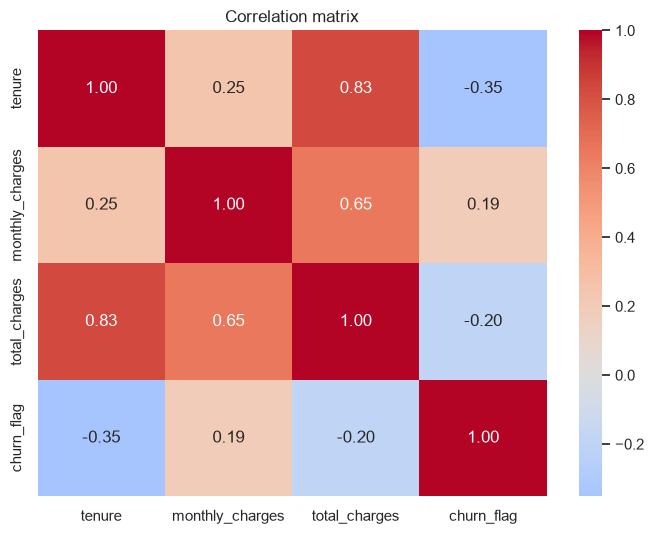

In [12]:
corr = df[["tenure", "monthly_charges", "total_charges", "churn_flag"]].corr()
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
save_png("08_heatmap_correlation")

### 9. Pairplot: multi-variable relationships

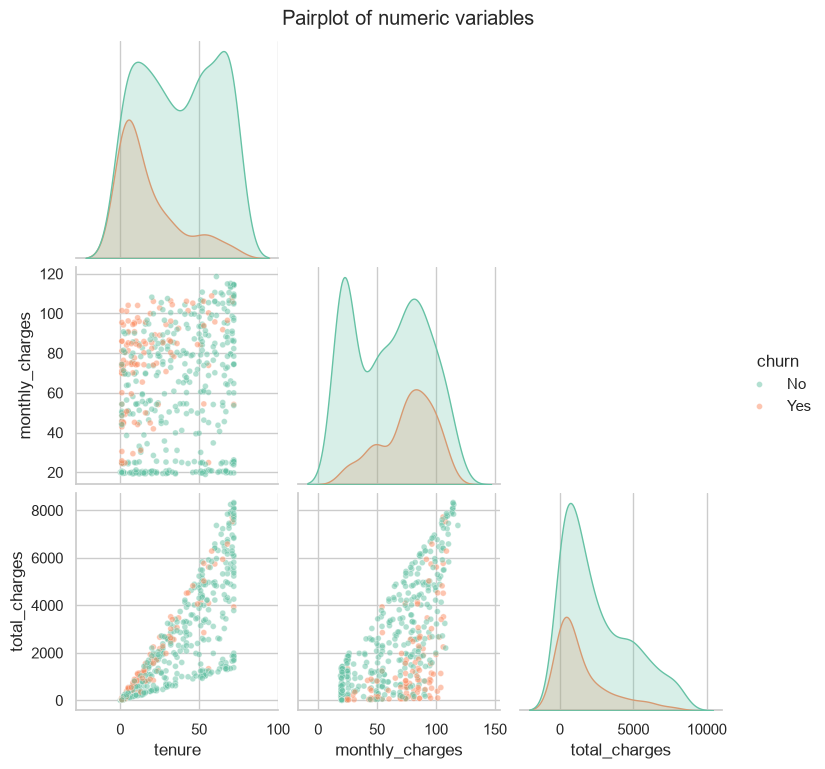

In [13]:
g = sns.pairplot(df.sample(min(500, len(df)), random_state=1),
                 vars=["tenure", "monthly_charges", "total_charges"], hue="churn", corner=True, plot_kws={"alpha": 0.5, "s": 18})
g.fig.suptitle("Pairplot of numeric variables", y=1.02)
g.savefig(PNG_DIR / "09_pairplot.png", dpi=130, bbox_inches="tight")
plt.show()

### 10. Boxen plot: monthly charges by contract

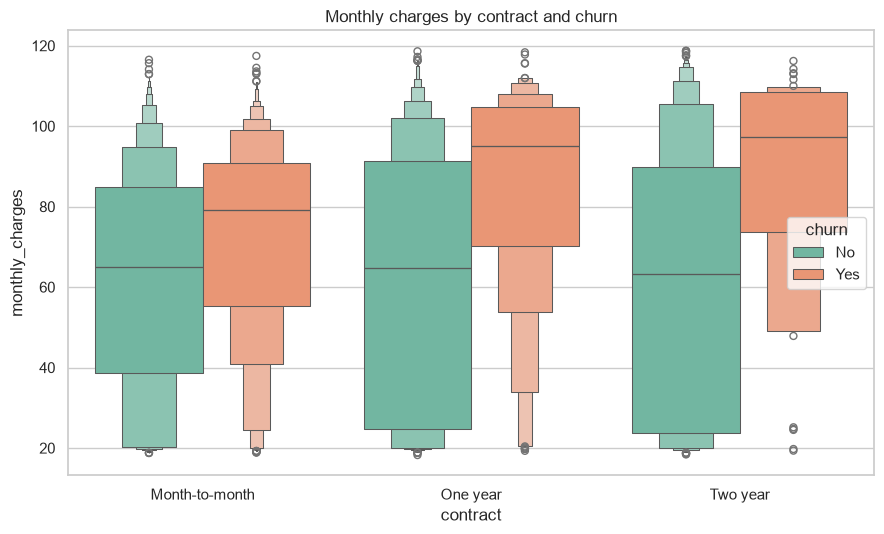

In [14]:
plt.figure(figsize=(9, 5.5))
sns.boxenplot(data=df, x="contract", y="monthly_charges", hue="churn")
plt.title("Monthly charges by contract and churn")
save_png("10_boxen_charges_by_contract")

### 11. FacetGrid: distribution of charges by contract and churn

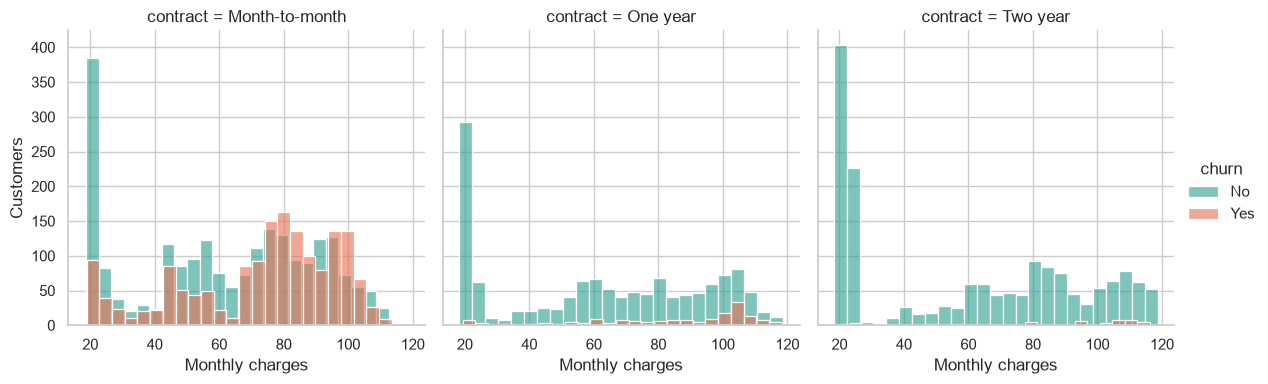

In [15]:
g = sns.FacetGrid(df, col="contract", hue="churn", height=4, aspect=1, palette={"No": "#2a9d8f", "Yes": "#e76f51"})
g.map(sns.histplot, "monthly_charges", bins=25, alpha=0.6)
g.add_legend()
g.set_axis_labels("Monthly charges", "Customers")
g.savefig(PNG_DIR / "11_facetgrid_charges.png", dpi=130, bbox_inches="tight")
plt.show()

### 12. Heatmap: churn rate by contract and internet service

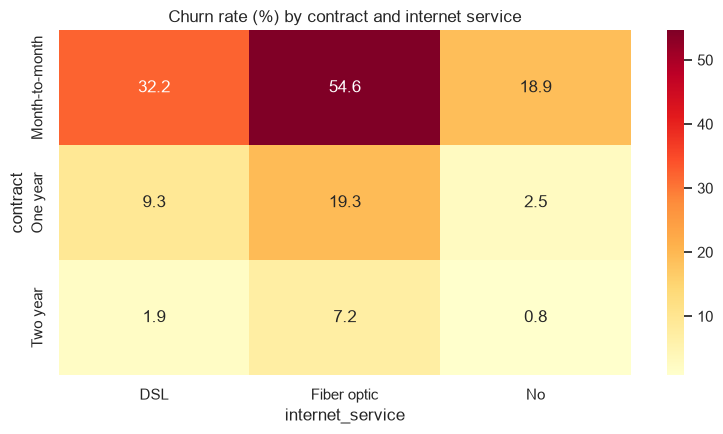

In [16]:
pivot = df.pivot_table(index="contract", columns="internet_service", values="churn_flag", aggfunc="mean").mul(100)
plt.figure(figsize=(8, 4.5))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="YlOrRd")
plt.title("Churn rate (%) by contract and internet service")
save_png("12_heatmap_contract_internet")

# C. Plotly (6 interactive charts, saved as HTML)
Open the saved `.html` files in any browser. Hover, zoom, click the legend and use the dropdowns.

### 13. Interactive scatter with dropdown filter

In [17]:
sample = df.sample(min(2000, len(df)), random_state=7)
contracts = sorted(sample["contract"].unique())
colors = ["#264653", "#2a9d8f", "#e76f51", "#e9c46a"]

fig = go.Figure()
for col, c in zip(colors, contracts):
    part = sample[sample["contract"] == c]
    fig.add_trace(go.Scatter(x=part["tenure"], y=part["monthly_charges"], mode="markers", name=c,
                             marker=dict(color=col, size=6, opacity=0.6),
                             text=part["customer_id"] + " | churn: " + part["churn"],
                             hovertemplate="%{text}<br>Tenure: %{x}<br>Bill: %{y}<extra></extra>"))

buttons = [dict(label="All contracts", method="update", args=[{"visible": [True] * len(contracts)}])]
for i, c in enumerate(contracts):
    vis = [j == i for j in range(len(contracts))]
    buttons.append(dict(label=c, method="update", args=[{"visible": vis}]))

fig.update_layout(title="Tenure vs monthly charges (use the dropdown to filter by contract)",
                  xaxis_title="Tenure (months)", yaxis_title="Monthly charges",
                  updatemenus=[dict(buttons=buttons, direction="down", x=1.0, xanchor="right", y=1.15)])
save_html(fig, "13_scatter_dropdown_filter")

Saved: c:\Users\Gaurav Pandey\OneDrive\Desktop\apexplanet\dashboards\html\13_scatter_dropdown_filter.html


### 14. Interactive bar chart with a dropdown to switch the category

In [18]:
cats = ["contract", "internet_service", "payment_method", "senior_citizen", "tenure_group"]
fig = go.Figure()
for i, cat in enumerate(cats):
    r = df.groupby(cat)["churn_flag"].mean().mul(100).round(1).reset_index()
    fig.add_trace(go.Bar(x=r[cat].astype(str), y=r["churn_flag"], name=cat, visible=(i == 0),
                         text=r["churn_flag"].astype(str) + "%", textposition="outside", marker_color="#e76f51"))

buttons = []
for i, cat in enumerate(cats):
    vis = [j == i for j in range(len(cats))]
    buttons.append(dict(label=cat, method="update",
                        args=[{"visible": vis}, {"title": f"Churn rate (%) by {cat}"}]))

fig.update_layout(title=f"Churn rate (%) by {cats[0]}", yaxis_title="Churn rate (%)", showlegend=False,
                  updatemenus=[dict(buttons=buttons, direction="down", x=1.0, xanchor="right", y=1.15)])
save_html(fig, "14_bar_dropdown_category")

Saved: c:\Users\Gaurav Pandey\OneDrive\Desktop\apexplanet\dashboards\html\14_bar_dropdown_category.html


### 15. Interactive line chart with a range slider

In [19]:
fig = px.line(by_tenure, x="tenure", y="churn_rate", markers=True,
              title="Churn rate by tenure month (drag the slider below to zoom)",
              labels={"tenure": "Tenure (months)", "churn_rate": "Churn rate (%)"})
fig.update_xaxes(rangeslider_visible=True)
save_html(fig, "15_line_range_slider")

Saved: c:\Users\Gaurav Pandey\OneDrive\Desktop\apexplanet\dashboards\html\15_line_range_slider.html


### 16. Donut chart: customers by internet service

In [20]:
fig = px.pie(df, names="internet_service", hole=0.5, title="Customers by internet service",
             color_discrete_sequence=["#264653", "#2a9d8f", "#e9c46a"])
fig.update_traces(textinfo="percent+label")
save_html(fig, "16_donut_internet_service")

Saved: c:\Users\Gaurav Pandey\OneDrive\Desktop\apexplanet\dashboards\html\16_donut_internet_service.html


### 17. Treemap: where is the revenue and the churn?

In [21]:
agg = (df.groupby(["contract", "internet_service"])
         .agg(monthly_revenue=("monthly_charges", "sum"), churn_rate=("churn_flag", lambda s: round(s.mean() * 100, 1)))
         .reset_index())
fig = px.treemap(agg, path=["contract", "internet_service"], values="monthly_revenue", color="churn_rate",
                 color_continuous_scale="RdYlGn_r", title="Monthly revenue (size) and churn rate % (colour)")
save_html(fig, "17_treemap_revenue_churn")

Saved: c:\Users\Gaurav Pandey\OneDrive\Desktop\apexplanet\dashboards\html\17_treemap_revenue_churn.html


### 18. Interactive dashboard page (KPI cards + 5 charts in one HTML file)

In [22]:
total      = len(df)
churn_rate = df["churn_flag"].mean() * 100
avg_bill   = df["monthly_charges"].mean()
revenue    = df["monthly_charges"].sum()

fig = make_subplots(
    rows=3, cols=4,
    specs=[[{"type": "indicator"}] * 4,
           [{"type": "xy", "colspan": 2}, None, {"type": "domain"}, {"type": "xy"}],
           [{"type": "xy", "colspan": 2}, None, {"type": "xy", "colspan": 2}, None]],
    row_heights=[0.18, 0.41, 0.41],
    subplot_titles=("", "", "", "", "Churn rate (%) by contract", "Customers by internet service", "Churn % by senior citizen",
                    "Churn rate (%) by tenure month", "Top 10 customers by lifetime revenue"))

for col, (title, value, fmt) in enumerate([("Total customers", total, ",.0f"), ("Churn rate (%)", churn_rate, ".1f"),
                                           ("Avg monthly bill", avg_bill, ".2f"), ("Monthly revenue", revenue, ",.0f")], start=1):
    fig.add_trace(go.Indicator(mode="number", value=value, title={"text": title}, number={"valueformat": fmt}), row=1, col=col)

c = df.groupby("contract")["churn_flag"].mean().mul(100).round(1).sort_values(ascending=False)
fig.add_trace(go.Bar(x=c.index, y=c.values, marker_color="#e76f51", text=c.values, textposition="outside"), row=2, col=1)

i = df["internet_service"].value_counts()
fig.add_trace(go.Pie(labels=i.index, values=i.values, hole=0.5), row=2, col=3)

s = df.groupby("senior_citizen")["churn_flag"].mean().mul(100).round(1)
fig.add_trace(go.Bar(x=s.index, y=s.values, marker_color="#2a9d8f", text=s.values, textposition="outside"), row=2, col=4)

fig.add_trace(go.Scatter(x=by_tenure["tenure"], y=by_tenure["churn_rate"], mode="lines", line=dict(color="#264653")), row=3, col=1)

top = df.nlargest(10, "total_charges").sort_values("total_charges")
fig.add_trace(go.Bar(x=top["total_charges"], y=top["customer_id"], orientation="h", marker_color="#e9c46a"), row=3, col=3)

fig.update_layout(title="Telco Customer Churn Dashboard (ApexPlanet Internship)", height=900, showlegend=False,
                  template="plotly_white")
save_html(fig, "18_dashboard_page")
# Also save a copy as the main shareable dashboard page
fig.write_html(HTML_DIR / "telco_dashboard.html", include_plotlyjs="cdn")

Saved: c:\Users\Gaurav Pandey\OneDrive\Desktop\apexplanet\dashboards\html\18_dashboard_page.html


# D. Summary

In [23]:
png = sorted(p.name for p in PNG_DIR.glob("*.png"))
html = sorted(p.name for p in HTML_DIR.glob("*.html"))
print(f"{len(png)} PNG files in {PNG_DIR}")
print(f"{len(html)} HTML files in {HTML_DIR}")
print(f"Total visualizations: {len(png) + len(html) - 1}")   # telco_dashboard.html is a copy of chart 18

12 PNG files in c:\Users\Gaurav Pandey\OneDrive\Desktop\apexplanet\reports\figures_task3
7 HTML files in c:\Users\Gaurav Pandey\OneDrive\Desktop\apexplanet\dashboards\html
Total visualizations: 18


### Key insights from the visuals (calculated from your data)

In [24]:
c = df.groupby("contract")["churn_flag"].mean().mul(100).round(1).sort_values(ascending=False)
t = df.groupby("tenure_group")["churn_flag"].mean().mul(100).round(1)
i = df.groupby("internet_service")["churn_flag"].mean().mul(100).round(1).sort_values(ascending=False)
mc = df.groupby("churn")["monthly_charges"].mean().round(2)

print(f"1. {c.index[0]} customers churn at {c.iloc[0]}%, vs {c.index[-1]} at {c.iloc[-1]}%.")
print(f"2. Churn falls with tenure: {t.iloc[0]}% in the first year vs {t.iloc[-1]}% after 49+ months.")
print(f"3. {i.index[0]} has the highest churn ({i.iloc[0]}%). Churned customers pay {mc['Yes']} per month vs {mc['No']} for loyal customers.")

1. Month-to-month customers churn at 42.7%, vs Two year at 2.8%.
2. Churn falls with tenure: 47.4% in the first year vs 9.5% after 49+ months.
3. Fiber optic has the highest churn (41.9%). Churned customers pay 74.44 per month vs 61.27 for loyal customers.


---
**Task 3 Part 1 complete.** Now build the Power BI / Tableau dashboard using `POWERBI_GUIDE.md`.